# Tugas Praktikum 6: Clustering (Advance)

**Dataset:** penguins.csv  
**Nama:** Lioneil Diyoel Trystan Tikupadang  
**NRP:** 5054251037  

## 0. Import library

In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import (AgglomerativeClustering,DBSCAN,SpectralClustering)
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score,rand_score,adjusted_rand_score,normalized_mutual_info_score)

import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)
plt.style.use("seaborn-v0_8-whitegrid")

## 1. Unduh dan Import Dataset

In [62]:
DATA_PATH = "penguins.csv"

df = pd.read_csv(DATA_PATH)

display(df.head())

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [63]:
print("Dimensi dataset (.shape):", df.shape)
print("\nInformasi atribut dan tipe data (.info()):")
df.info()

Dimensi dataset (.shape): (344, 8)

Informasi atribut dan tipe data (.info()):
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB


## 2. Eksplorasi dan Pembersihan Data

In [64]:
print("Jumlah nilai kosong pada tiap kolom (.isna().sum()):")
missing_series = df.isna().sum()
display(missing_series.to_frame("Jumlah Missing Value"))

Jumlah nilai kosong pada tiap kolom (.isna().sum()):


,Jumlah Missing Value
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11
year,0


In [65]:
feature_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
target_col = 'species'

n_before = len(df)
df_clean = df.dropna(subset=feature_cols + [target_col]).copy()
df_clean.reset_index(drop=True, inplace=True)
n_after = len(df_clean)

print(f"Jumlah baris sebelum pembersihan : {n_before}")
print(f"Jumlah baris sesudah pembersihan : {n_after}")
print(f"Jumlah baris yang dihapus        : {n_before - n_after}")

Jumlah baris sebelum pembersihan : 344
Jumlah baris sesudah pembersihan : 342
Jumlah baris yang dihapus        : 2


Menghapus baris yang nilainya kosong pada salah satu dari empat kolom numerik atau pada kolom `species`.

Jumlah data per spesies:


,Jumlah Data,Persentase (%)
species,,
Adelie,151,44.15
Gentoo,123,35.96
Chinstrap,68,19.88


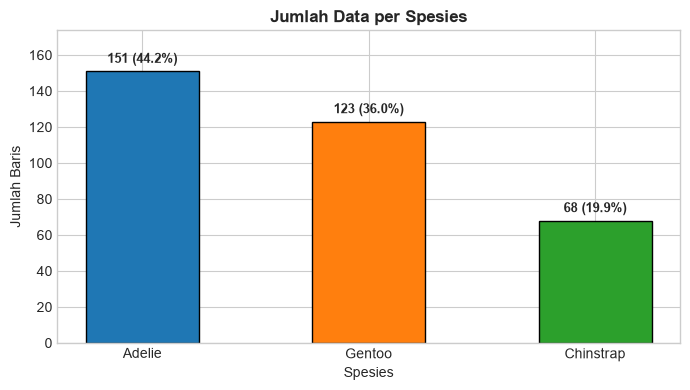

In [66]:
species_counts = df_clean['species'].value_counts()
species_pct = df_clean['species'].value_counts(normalize=True) * 100

species_table = pd.DataFrame({
    "Jumlah Data": species_counts,
    "Persentase (%)": species_pct.round(2)
})
print("Jumlah data per spesies:")
display(species_table)

plt.figure(figsize=(7, 4))
bars = plt.bar(species_counts.index, species_counts.values, color=["#1f77b4", "#ff7f0e", "#2ca02c"], edgecolor="black", width=0.5)
plt.title("Jumlah Data per Spesies", fontsize=12, fontweight="bold")
plt.xlabel("Spesies")
plt.ylabel("Jumlah Baris")
plt.ylim(0, max(species_counts.values) * 1.15)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 3, f"{int(yval)} ({yval/n_after*100:.1f}%)", 
             ha="center", va="bottom", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.show()

In [67]:
print("Statistik deskriptif empat kolom numerik (.describe()):")
display(df_clean[feature_cols].describe().round(2))

Statistik deskriptif empat kolom numerik (.describe()):


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.00,342.00,342.00,342.00
mean,43.92,17.15,200.92,4201.75
std,5.46,1.97,14.06,801.95
min,32.10,13.10,172.00,2700.00
25%,39.22,15.60,190.00,3550.00
50%,44.45,17.30,197.00,4050.00
75%,48.50,18.70,213.00,4750.00
max,59.60,21.50,231.00,6300.00


**Catatan Perbedaan Skala Antar Kolom:**
Berdasarkan statistik deskriptif di atas, terlihat perbedaan skala yang sangat mencolok:
* `body_mass_g` memiliki nilai rata-rata **4.201,75 gram** dengan rentang nilai dari **2.700 hingga 6.300 gram** (rentang = 3.600 gram).
* `flipper_length_mm` memiliki nilai rata-rata **200,92 mm** dengan rentang **172 hingga 231 mm** (rentang = 59 mm).
* `bill_length_mm` memiliki nilai rata-rata **43,92 mm** dengan rentang **32,10 hingga 59,60 mm** (rentang = 27,50 mm).
* `bill_depth_mm` memiliki nilai rata-rata **17,15 mm** dengan rentang **13,10 hingga 21,50 mm** (rentang = 8,40 mm).

Perbedaan satuan (gram vs milimeter) serta besaran varians antar kolom akan membuat perhitungan jarak Euclidean didominasi mutlak oleh `body_mass_g` apabila data tidak distandardisasi terlebih dahulu.

Membuat scatter plot awal, `flipper_length_mm` terhadap `bill_length_mm`, untuk melihat sebaran data sebelum clustering.

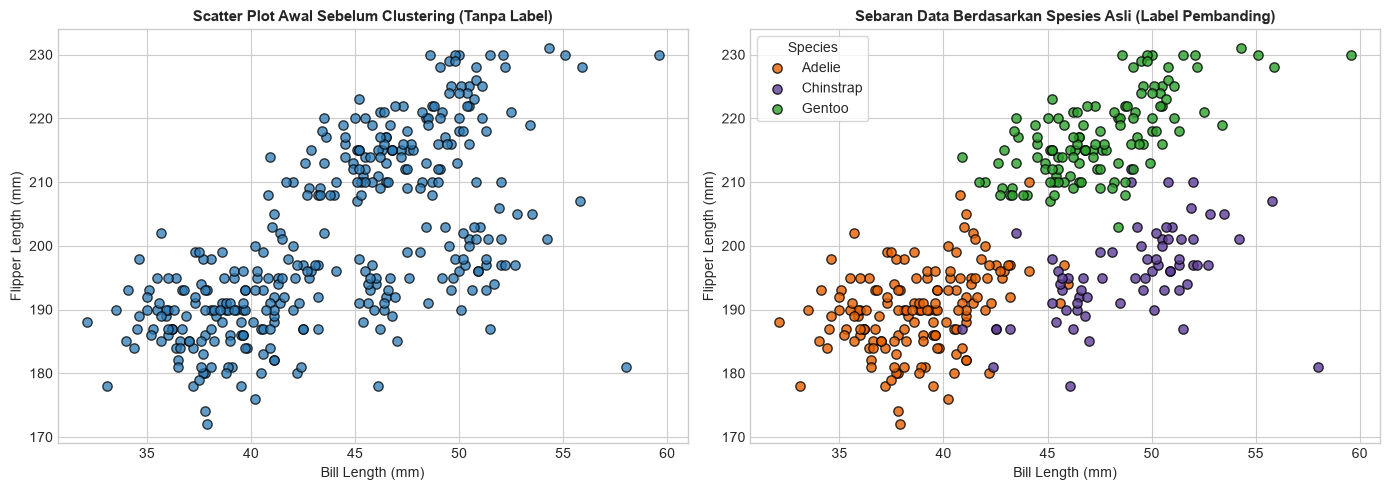

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter plot sebaran data sebelum clustering (tanpa label)
axes[0].scatter(
    df_clean['bill_length_mm'],
    df_clean['flipper_length_mm'],
    c='#2c7bb6',
    alpha=0.75,
    edgecolors='k',
    s=45
)
axes[0].set_title("Scatter Plot Awal Sebelum Clustering (Tanpa Label)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Bill Length (mm)")
axes[0].set_ylabel("Flipper Length (mm)")

# Scatter plot sebaran data dengan warna per spesies sebagai pembanding
colors_map = {'Adelie': '#e66101', 'Chinstrap': '#5e3c99', 'Gentoo': '#2ca02c'}
for sp, grp in df_clean.groupby('species'):
    axes[1].scatter(
        grp['bill_length_mm'],
        grp['flipper_length_mm'],
        label=sp,
        c=colors_map[sp],
        alpha=0.8,
        edgecolors='k',
        s=45
    )
axes[1].set_title("Sebaran Data Berdasarkan Spesies Asli (Label Pembanding)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Bill Length (mm)")
axes[1].set_ylabel("Flipper Length (mm)")
axes[1].legend(title="Species", frameon=True)

plt.tight_layout()
plt.show()

## 3. Standardisasi Data
Melakukan standardisasi `X` dengan z-score (`StandardScaler`) karena satuan antar kolom berbeda jauh (milimeter dan gram). Seluruh algoritma clustering dijalankan pada data hasil standardisasi.

In [69]:
# Pisahkan 4 kolom numerik sebagai X dan kolom species sebagai y
X = df_clean[feature_cols].copy()
y = df_clean[target_col].copy()

# Standardisasi X dengan z-score menggunakan StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Verifikasi statistik setelah standardisasi (mean mendekati 0, std mendekati 1)
df_scaled = pd.DataFrame(X_scaled, columns=feature_cols)
print("Statistik deskriptif X setelah standardisasi (StandardScaler):")
display(df_scaled.describe().round(4))

Statistik deskriptif X setelah standardisasi (StandardScaler):


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.0000,342.0000,342.0000,342.0000
mean,0.0000,0.0000,-0.0000,0.0000
std,1.0015,1.0015,1.0015,1.0015
min,-2.1685,-2.0544,-2.0593,-1.8754
25%,-0.8616,-0.7866,-0.7774,-0.8139
50%,0.0969,0.0755,-0.2788,-0.1895
75%,0.8398,0.7854,0.8607,0.6846
max,2.8759,2.2054,2.1426,2.6202


## 4. Penerapan Algoritma
Menerapkan empat algoritma clustering lanjutan pada data hasil standardisasi:
1. **Agglomerative Clustering** dengan 3 kluster (menampilkan dendrogram dan jenis linkage).
2. **DBSCAN** mulai dari `eps=0.5` dan `MinPts=5`, mencoba beberapa nilai `eps` lain, serta mencatat jumlah kluster dan titik noise.
3. **Gaussian Mixture Models (GMM)** dengan 3 komponen.
4. **Spectral Clustering** dengan 3 kluster.
5. Membuat scatter plot hasil tiap algoritma (satu warna per kluster, khusus DBSCAN diberi warna terpisah untuk noise label -1).

### 4.1. Agglomerative Clustering
* Menerapkan Agglomerative Clustering dengan jumlah kluster 3.
* Menampilkan dendrogram dan menyebutkan jenis linkage yang digunakan: **Ward linkage** (`method='ward'`). Ward linkage meminimalkan varians total di dalam kluster pada setiap tahap penggabungan.

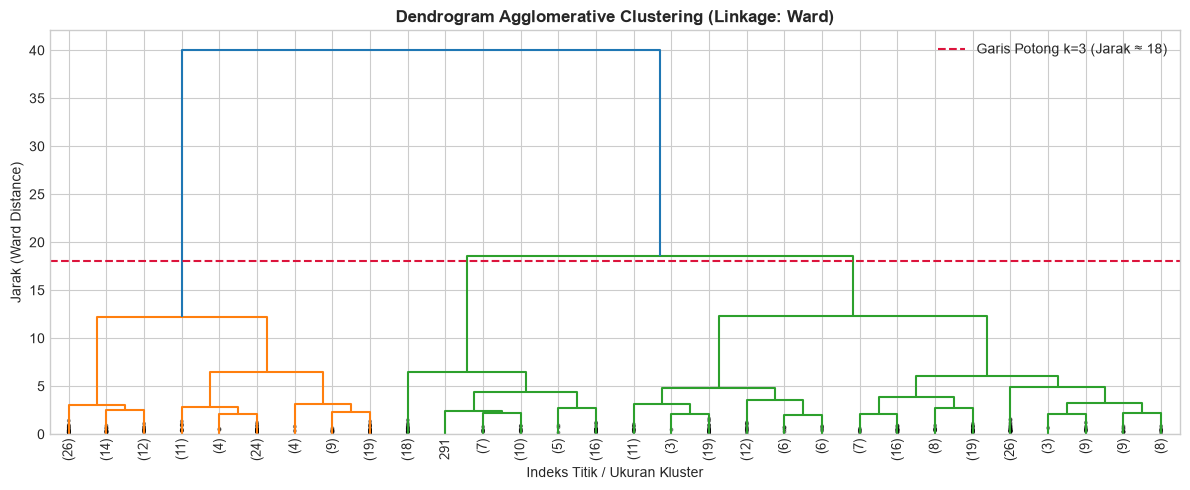

Jenis linkage yang dipakai: Ward linkage ('ward')
Distribusi anggota tiap kluster Agglomerative:


,Jumlah Titik
Kluster 0,162
Kluster 1,123
Kluster 2,57


In [70]:
# Membuat matriks linkage menggunakan metode Ward
linkage_matrix = linkage(X_scaled, method='ward')

# Menampilkan visualisasi dendrogram
plt.figure(figsize=(12, 5))
dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=9,
    show_contracted=True
)
plt.title("Dendrogram Agglomerative Clustering (Linkage: Ward)", fontsize=12, fontweight="bold")
plt.xlabel("Indeks Titik / Ukuran Kluster")
plt.ylabel("Jarak (Ward Distance)")
plt.axhline(y=18, color='crimson', linestyle='--', linewidth=1.5, label='Garis Potong k=3 (Jarak ≈ 18)')
plt.legend()
plt.tight_layout()
plt.show()

# Penerapan Agglomerative Clustering dengan 3 kluster
agg_model = AgglomerativeClustering(n_clusters=3, linkage='ward')
agg_labels = agg_model.fit_predict(X_scaled)

print("Jenis linkage yang dipakai: Ward linkage ('ward')")
print("Distribusi anggota tiap kluster Agglomerative:")
display(pd.Series(agg_labels).value_counts().sort_index().rename(lambda x: f"Kluster {x}").to_frame("Jumlah Titik"))

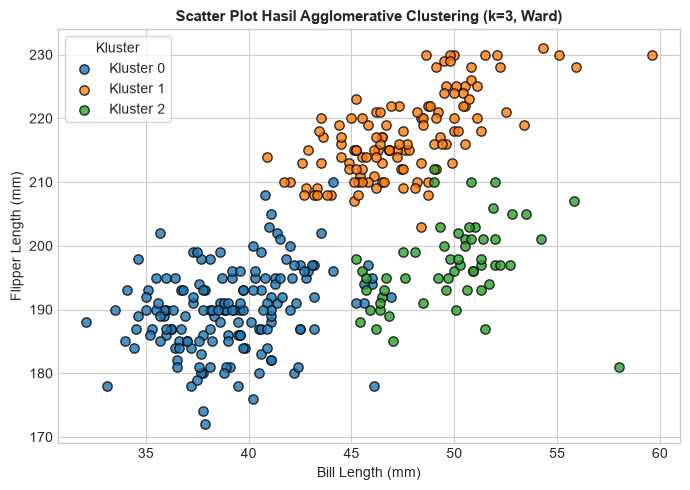

In [71]:
plt.figure(figsize=(7, 5))
colors_cluster = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]
for cl in np.unique(agg_labels):
    mask = (agg_labels == cl)
    plt.scatter(
        df_clean.loc[mask, 'bill_length_mm'],
        df_clean.loc[mask, 'flipper_length_mm'],
        label=f"Kluster {cl}",
        c=colors_cluster[cl],
        alpha=0.8,
        edgecolors='k',
        s=45
    )
plt.title("Scatter Plot Hasil Agglomerative Clustering (k=3, Ward)", fontsize=11, fontweight="bold")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Flipper Length (mm)")
plt.legend(title="Kluster", frameon=True)
plt.tight_layout()
plt.show()

### 4.2. DBSCAN
* Menerapkan DBSCAN mulai dari `eps=0.5` dan `MinPts=5` (`min_samples=5`).
* Mencoba beberapa nilai `eps` lain (`[0.3, 0.4, 0.5, 0.6, 0.7, 0.8]`), lalu mencatat jumlah kluster dan jumlah titik noise yang dihasilkan pada tiap nilai ke dalam tabel.

In [72]:
eps_values = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
dbscan_table_records = []

for eps in eps_values:
    db = DBSCAN(eps=eps, min_samples=5).fit(X_scaled)
    lbls = db.labels_
    unique_lbls = set(lbls)
    n_clusters = len(unique_lbls) - (1 if -1 in lbls else 0)
    n_noise = list(lbls).count(-1)
    
    dbscan_table_records.append({
        "Epsilon (eps)": eps,
        "MinPts": 5,
        "Jumlah Kluster": n_clusters,
        "Jumlah Titik Noise": n_noise,
        "Persentase Noise (%)": round((n_noise / len(X_scaled)) * 100, 2)
    })

dbscan_exp_df = pd.DataFrame(dbscan_table_records)
print("Catatan Hasil Eksplorasi Nilai Epsilon pada DBSCAN (MinPts=5):")
display(dbscan_exp_df)

Catatan Hasil Eksplorasi Nilai Epsilon pada DBSCAN (MinPts=5):


,Epsilon (eps),MinPts,Jumlah Kluster,Jumlah Titik Noise,Persentase Noise (%)
0,0.3,5,4,317,92.69
1,0.4,5,10,171,50.00
2,0.5,5,4,69,20.18
3,0.6,5,2,33,9.65
4,0.7,5,2,16,4.68
5,0.8,5,2,5,1.46


Hasil DBSCAN (eps=0.5, MinPts=5):
- Jumlah kluster terbentuk : 4
- Jumlah titik noise (-1)  : 69 titik (20.18%)


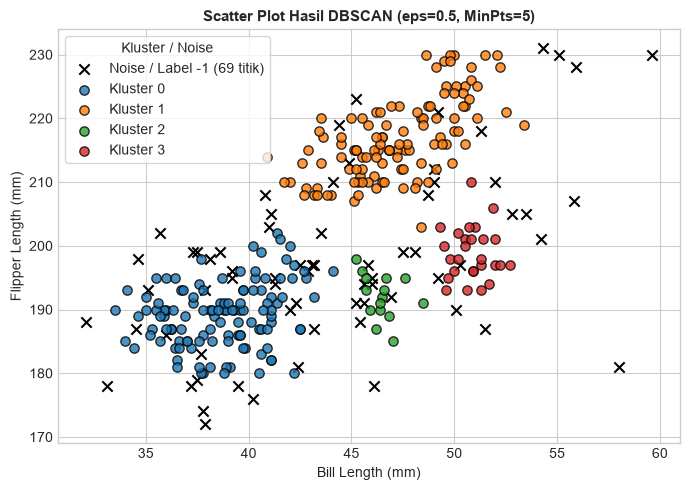

In [73]:
# Terapkan DBSCAN baseline: eps=0.5 dan MinPts=5
dbscan_model = DBSCAN(eps=0.5, min_samples=5)
dbscan_labels = dbscan_model.fit_predict(X_scaled)

n_db_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_db_noise = list(dbscan_labels).count(-1)

print(f"Hasil DBSCAN (eps=0.5, MinPts=5):")
print(f"- Jumlah kluster terbentuk : {n_db_clusters}")
print(f"- Jumlah titik noise (-1)  : {n_db_noise} titik ({n_db_noise/len(X_scaled)*100:.2f}%)")

# Scatter plot hasil DBSCAN (warna terpisah untuk titik noise label -1)
plt.figure(figsize=(7, 5))
for cl in np.unique(dbscan_labels):
    mask = (dbscan_labels == cl)
    if cl == -1:
        plt.scatter(
            df_clean.loc[mask, 'bill_length_mm'],
            df_clean.loc[mask, 'flipper_length_mm'],
            c='black',
            marker='x',
            s=55,
            linewidths=1.5,
            label=f"Noise / Label -1 ({np.sum(mask)} titik)"
        )
    else:
        plt.scatter(
            df_clean.loc[mask, 'bill_length_mm'],
            df_clean.loc[mask, 'flipper_length_mm'],
            label=f"Kluster {cl}",
            c=colors_cluster[cl % len(colors_cluster)],
            alpha=0.8,
            edgecolors='k',
            s=45
        )
plt.title("Scatter Plot Hasil DBSCAN (eps=0.5, MinPts=5)", fontsize=11, fontweight="bold")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Flipper Length (mm)")
plt.legend(title="Kluster / Noise", frameon=True)
plt.tight_layout()
plt.show()

### 4.3. Gaussian Mixture Models (GMM)
* Menerapkan Gaussian Mixture Models (GMM) dengan 3 komponen (`n_components=3`).
* Membuat scatter plot hasil pengelompokan GMM.

Distribusi anggota tiap kluster GMM (3 komponen):


,Jumlah Titik
Kluster 0,67
Kluster 1,123
Kluster 2,152


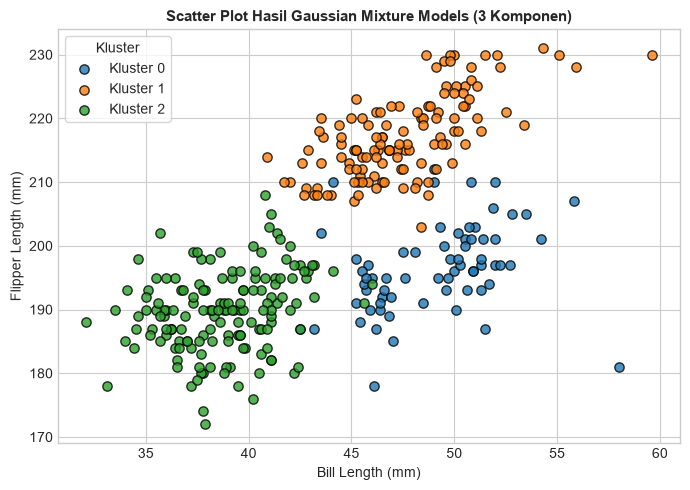

In [74]:
# Terapkan GMM dengan 3 komponen
gmm_model = GaussianMixture(n_components=3, random_state=RANDOM_STATE)
gmm_labels = gmm_model.fit_predict(X_scaled)

print("Distribusi anggota tiap kluster GMM (3 komponen):")
display(pd.Series(gmm_labels).value_counts().sort_index().rename(lambda x: f"Kluster {x}").to_frame("Jumlah Titik"))

# Scatter plot hasil GMM
plt.figure(figsize=(7, 5))
for cl in np.unique(gmm_labels):
    mask = (gmm_labels == cl)
    plt.scatter(
        df_clean.loc[mask, 'bill_length_mm'],
        df_clean.loc[mask, 'flipper_length_mm'],
        label=f"Kluster {cl}",
        c=colors_cluster[cl],
        alpha=0.8,
        edgecolors='k',
        s=45
    )
plt.title("Scatter Plot Hasil Gaussian Mixture Models (3 Komponen)", fontsize=11, fontweight="bold")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Flipper Length (mm)")
plt.legend(title="Kluster", frameon=True)
plt.tight_layout()
plt.show()

### 4.4. Spectral Clustering
* Menerapkan Spectral Clustering dengan 3 kluster (`n_clusters=3`).
* Membuat scatter plot hasil pengelompokan Spectral Clustering.

Distribusi anggota tiap kluster Spectral Clustering (3 kluster):


,Jumlah Titik
Kluster 0,176
Kluster 1,123
Kluster 2,43


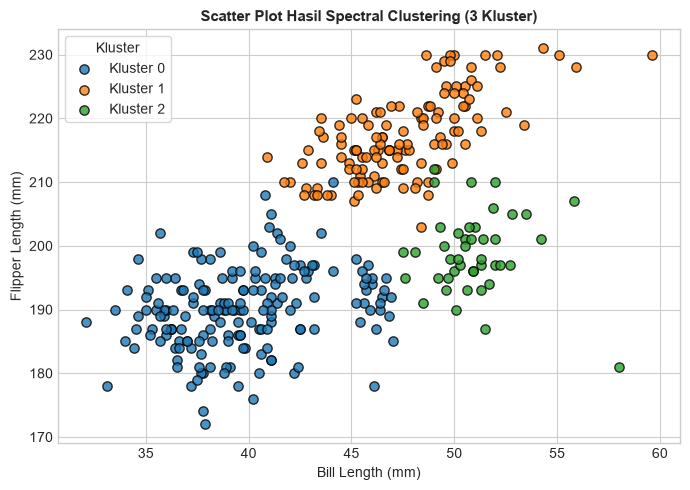

In [75]:
# Terapkan Spectral Clustering dengan 3 kluster
spec_model = SpectralClustering(n_clusters=3, random_state=RANDOM_STATE)
spec_labels = spec_model.fit_predict(X_scaled)

print("Distribusi anggota tiap kluster Spectral Clustering (3 kluster):")
display(pd.Series(spec_labels).value_counts().sort_index().rename(lambda x: f"Kluster {x}").to_frame("Jumlah Titik"))

# Scatter plot hasil Spectral Clustering
plt.figure(figsize=(7, 5))
for cl in np.unique(spec_labels):
    mask = (spec_labels == cl)
    plt.scatter(
        df_clean.loc[mask, 'bill_length_mm'],
        df_clean.loc[mask, 'flipper_length_mm'],
        label=f"Kluster {cl}",
        c=colors_cluster[cl],
        alpha=0.8,
        edgecolors='k',
        s=45
    )
plt.title("Scatter Plot Hasil Spectral Clustering (3 Kluster)", fontsize=11, fontweight="bold")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Flipper Length (mm)")
plt.legend(title="Kluster", frameon=True)
plt.tight_layout()
plt.show()

### 4.5. Perbandingan Visual Scatter Plot Keempat Algoritma
Menampilkan scatter plot hasil keempat algoritma berdampingan dengan label spesies asli (*Ground Truth*) untuk memudahkan analisis visual.

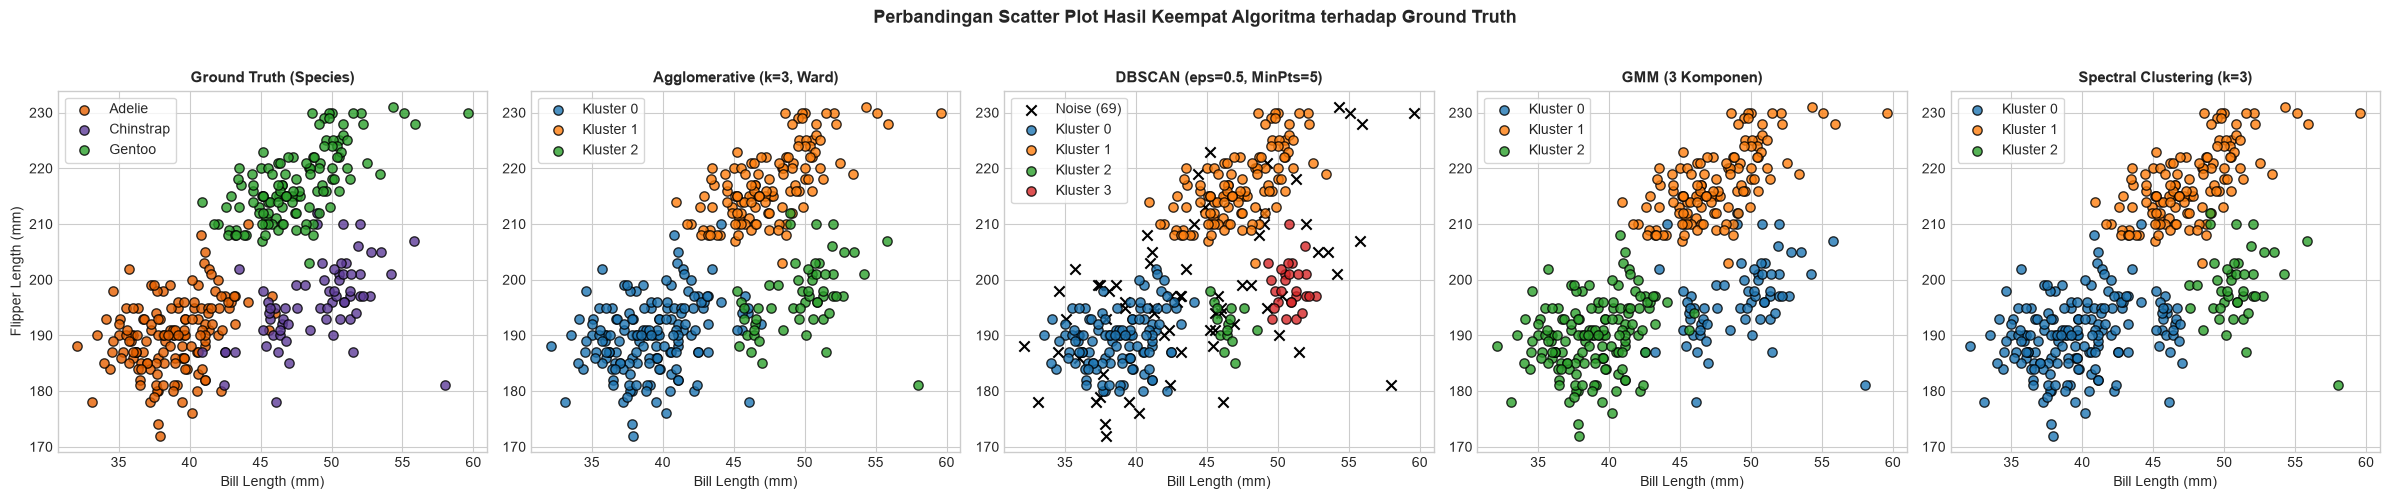

In [76]:
fig, axes = plt.subplots(1, 5, figsize=(24, 4.8))

# 1. Ground Truth
for sp, col in colors_map.items():
    mask = (df_clean['species'] == sp)
    axes[0].scatter(
        df_clean.loc[mask, 'bill_length_mm'],
        df_clean.loc[mask, 'flipper_length_mm'],
        c=col, label=sp, alpha=0.8, edgecolors='k', s=45
    )
axes[0].set_title("Ground Truth (Species)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Bill Length (mm)")
axes[0].set_ylabel("Flipper Length (mm)")
axes[0].legend(frameon=True, loc="upper left")

# 2. Agglomerative
for cl in np.unique(agg_labels):
    mask = (agg_labels == cl)
    axes[1].scatter(
        df_clean.loc[mask, 'bill_length_mm'],
        df_clean.loc[mask, 'flipper_length_mm'],
        c=colors_cluster[cl], label=f"Kluster {cl}", alpha=0.8, edgecolors='k', s=45
    )
axes[1].set_title("Agglomerative (k=3, Ward)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Bill Length (mm)")
axes[1].legend(frameon=True, loc="upper left")

# 3. DBSCAN
for cl in np.unique(dbscan_labels):
    mask = (dbscan_labels == cl)
    if cl == -1:
        axes[2].scatter(
            df_clean.loc[mask, 'bill_length_mm'],
            df_clean.loc[mask, 'flipper_length_mm'],
            c='black', marker='x', s=55, linewidths=1.5, label=f"Noise ({np.sum(mask)})"
        )
    else:
        axes[2].scatter(
            df_clean.loc[mask, 'bill_length_mm'],
            df_clean.loc[mask, 'flipper_length_mm'],
            c=colors_cluster[cl % len(colors_cluster)], label=f"Kluster {cl}", alpha=0.8, edgecolors='k', s=45
        )
axes[2].set_title("DBSCAN (eps=0.5, MinPts=5)", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Bill Length (mm)")
axes[2].legend(frameon=True, loc="upper left")

# 4. GMM
for cl in np.unique(gmm_labels):
    mask = (gmm_labels == cl)
    axes[3].scatter(
        df_clean.loc[mask, 'bill_length_mm'],
        df_clean.loc[mask, 'flipper_length_mm'],
        c=colors_cluster[cl], label=f"Kluster {cl}", alpha=0.8, edgecolors='k', s=45
    )
axes[3].set_title("GMM (3 Komponen)", fontsize=11, fontweight="bold")
axes[3].set_xlabel("Bill Length (mm)")
axes[3].legend(frameon=True, loc="upper left")

# 5. Spectral Clustering
for cl in np.unique(spec_labels):
    mask = (spec_labels == cl)
    axes[4].scatter(
        df_clean.loc[mask, 'bill_length_mm'],
        df_clean.loc[mask, 'flipper_length_mm'],
        c=colors_cluster[cl], label=f"Kluster {cl}", alpha=0.8, edgecolors='k', s=45
    )
axes[4].set_title("Spectral Clustering (k=3)", fontsize=11, fontweight="bold")
axes[4].set_xlabel("Bill Length (mm)")
axes[4].legend(frameon=True, loc="upper left")

plt.suptitle("Perbandingan Scatter Plot Hasil Keempat Algoritma terhadap Ground Truth", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

## 5. Evaluasi Hasil Clustering
* **Silhouette Score:** Menghitung Silhouette Score untuk tiap algoritma. Untuk DBSCAN, dihitung tanpa mengikutsertakan titik noise dan disebutkan berapa titik yang dibuang.
* **Rand Index dan NMI:** Menghitung Rand Index dan Normalized Mutual Information (NMI) terhadap kolom `species`.
* **Uji Kestabilan:** Menjalankan ulang tiap algoritma pada 90% data yang diambil acak sebanyak tiga kali, lalu membandingkan hasilnya dengan hasil pada data penuh.
* **Tabel Perbandingan:** Merangkum seluruh nilai evaluasi dalam satu tabel perbandingan.

### 5.1. Evaluasi Internal (Silhouette Score) dan Eksternal (Rand Index & NMI)

In [77]:
models_labels = {
    "Agglomerative Clustering": agg_labels,
    "DBSCAN (eps=0.5, MinPts=5)": dbscan_labels,
    "Gaussian Mixture Models": gmm_labels,
    "Spectral Clustering": spec_labels
}

evaluation_list = []

for name, labels in models_labels.items():
    mask = (labels != -1)
    n_noise_dropped = np.sum(~mask)
    n_valid_k = len(set(labels[mask]))
    
    # Silhouette Score (internal) dihitung tanpa titik noise
    if n_valid_k >= 2:
        sil = silhouette_score(X_scaled[mask], labels[mask])
    else:
        sil = np.nan
        
    # Rand Index dan NMI (eksternal) terhadap kolom species
    ri = rand_score(y[mask], labels[mask])
    ari = adjusted_rand_score(y[mask], labels[mask])
    nmi = normalized_mutual_info_score(y[mask], labels[mask])
    
    evaluation_list.append({
        "Algoritma": name,
        "Jumlah Kluster": n_valid_k,
        "Jumlah Titik Noise Dibuang": n_noise_dropped,
        "Silhouette Score": sil,
        "Rand Index": ri,
        "Adjusted Rand Index (ARI)": ari,
        "Normalized Mutual Info (NMI)": nmi
    })

eval_full_df = pd.DataFrame(evaluation_list).set_index("Algoritma")
display(eval_full_df.round(4))

dbscan_dropped = eval_full_df.loc["DBSCAN (eps=0.5, MinPts=5)", "Jumlah Titik Noise Dibuang"]
print(f"Catatan DBSCAN: Silhouette Score dihitung tanpa {dbscan_dropped} titik noise yang dibuang ({dbscan_dropped/len(X_scaled)*100:.2f}% dari total data).")

,Jumlah Kluster,Jumlah Titik Noise Dibuang,Silhouette Score,Rand Index,Adjusted Rand Index (ARI),Normalized Mutual Info (NMI)
Algoritma,,,,,,
Agglomerative Clustering,3,0,0.4541,0.9608,0.9159,0.9007
"DBSCAN (eps=0.5, MinPts=5)",4,69,0.4235,0.9764,0.9495,0.9105
Gaussian Mixture Models,3,0,0.4545,0.9817,0.9603,0.9349
Spectral Clustering,3,0,0.4624,0.9168,0.8248,0.8312


Catatan DBSCAN: Silhouette Score dihitung tanpa 69 titik noise yang dibuang (20.18% dari total data).


### 5.2. Uji Kestabilan (Stability Test)
Menjalankan ulang tiap algoritma pada 90% data yang diambil acak (`sample(frac=0.9)`), sebanyak **tiga kali** (Run 1, Run 2, Run 3) dengan random seed berbeda:
* Hasil pengelompokan pada 90% data dibandingkan dengan hasil pada data penuh pada indeks observasi yang sama menggunakan **Adjusted Rand Index (ARI Agreement)**.
* Nilai kesesuaian mendekati 1,0 menunjukkan bahwa struktur kluster yang dihasilkan stabil dan konsisten terhadap perubahan kecil pada dataset.

In [78]:
seeds = [42, 100, 2024]
stability_agreement = {name: [] for name in models_labels}
stability_run_records = []

factories = {
    "Agglomerative Clustering": lambda: AgglomerativeClustering(n_clusters=3, linkage='ward'),
    "DBSCAN (eps=0.5, MinPts=5)": lambda: DBSCAN(eps=0.5, min_samples=5),
    "Gaussian Mixture Models": lambda: GaussianMixture(n_components=3, random_state=RANDOM_STATE),
    "Spectral Clustering": lambda: SpectralClustering(n_clusters=3, random_state=RANDOM_STATE)
}

for run_i, s in enumerate(seeds, start=1):
    sub_df = df_clean.sample(frac=0.9, random_state=s)
    sub_idx = sub_df.index.values
    X_sub = X_scaled[sub_idx]
    y_sub = y.iloc[sub_idx].values
    
    for name, factory_fn in factories.items():
        sub_m = factory_fn()
        sub_preds = sub_m.fit_predict(X_sub)
        full_preds_sub = models_labels[name][sub_idx]
        
        # Bandingkan hasil subsample dengan hasil data penuh pada indeks yang sama
        agr_ari = adjusted_rand_score(full_preds_sub, sub_preds)
        stability_agreement[name].append(agr_ari)
        
        mask_sub = (sub_preds != -1)
        sub_sil = silhouette_score(X_sub[mask_sub], sub_preds[mask_sub]) if len(set(sub_preds[mask_sub])) > 1 else np.nan
        sub_nmi = normalized_mutual_info_score(y_sub[mask_sub], sub_preds[mask_sub])
        
        stability_run_records.append({
            "Iterasi Uji": f"Run {run_i} (Seed {s})",
            "Algoritma": name,
            "Ukuran Sampel (90%)": len(sub_idx),
            "Kesesuaian dg Data Penuh (ARI)": agr_ari,
            "Silhouette Subsample": sub_sil,
            "NMI Subsample": sub_nmi
        })

stability_df = pd.DataFrame(stability_run_records)
print("Hasil Uji Kestabilan pada Tiga Kali Pengambilan 90% Data Acak:")
display(stability_df.set_index(["Iterasi Uji", "Algoritma"]).round(4))

Hasil Uji Kestabilan pada Tiga Kali Pengambilan 90% Data Acak:


Ukuran Sampel (90%)  \
Iterasi Uji       Algoritma                                         
Run 1 (Seed 42)   Agglomerative Clustering                    308   
                  DBSCAN (eps=0.5, MinPts=5)                  308   
                  Gaussian Mixture Models                     308   
                  Spectral Clustering                         308   
Run 2 (Seed 100)  Agglomerative Clustering                    308   
                  DBSCAN (eps=0.5, MinPts=5)                  308   
                  Gaussian Mixture Models                     308   
                  Spectral Clustering                         308   
Run 3 (Seed 2024) Agglomerative Clustering                    308   
                  DBSCAN (eps=0.5, MinPts=5)                  308   
                  Gaussian Mixture Models                     308   
                  Spectral Clustering                         308   

                                              Kesesuaian dg Data Penuh (ARI)  \
Iterasi Uji       Algoritma                                                    
Run 1 (Seed 42)   Agglomerative Clustering                            0.6467   
                  DBSCAN (eps=0.5, MinPts=5)                          0.9216   
                  Gaussian Mixture Models                             0.9910   
                  Spectral Clustering                                 1.0000   
Run 2 (Seed 100)  Agglomerative Clustering                            0.9238   
                  DBSCAN (eps=0.5, MinPts=5)                          0.9278   
                  Gaussian Mixture Models                             1.0000   
                  Spectral Clustering                                 0.9831   
Run 3 (Seed 2024) Agglomerative Clustering                            0.9411   
                  DBSCAN (eps=0.5, MinPts=5)                          0.9717   
                  Gaussian Mixture Models                             0.9912   
                  Spectral Clustering                                 1.0000   

                                              Silhouette Subsample  \
Iterasi Uji       Algoritma                                          
Run 1 (Seed 42)   Agglomerative Clustering                  0.4261   
                  DBSCAN (eps=0.5, MinPts=5)                0.4403   
                  Gaussian Mixture Models                   0.4496   
                  Spectral Clustering                       0.4614   
Run 2 (Seed 100)  Agglomerative Clustering                  0.4492   
                  DBSCAN (eps=0.5, MinPts=5)                0.4280   
                  Gaussian Mixture Models                   0.4514   
                  Spectral Clustering                       0.4610   
Run 3 (Seed 2024) Agglomerative Clustering                  0.4615   
                  DBSCAN (eps=0.5, MinPts=5)                0.4405   
                  Gaussian Mixture Models                   0.4582   
                  Spectral Clustering                       0.4684   

                                              NMI Subsample  
Iterasi Uji       Algoritma                                  
Run 1 (Seed 42)   Agglomerative Clustering           0.6925  
                  DBSCAN (eps=0.5, MinPts=5)         0.9060  
                  Gaussian Mixture Models            0.9404  
                  Spectral Clustering                0.8245  
Run 2 (Seed 100)  Agglomerative Clustering           0.9089  
                  DBSCAN (eps=0.5, MinPts=5)         0.9037  
                  Gaussian Mixture Models            0.9298  
                  Spectral Clustering                0.8179  
Run 3 (Seed 2024) Agglomerative Clustering           0.9019  
                  DBSCAN (eps=0.5, MinPts=5)         0.9104  
                  Gaussian Mixture Models            0.9534  
                  Spectral Clustering                0.8307

### 5.3. Tabel Perbandingan Seluruh Nilai Evaluasi
Merangkum seluruh nilai evaluasi internal (Silhouette Score), evaluasi eksternal (Rand Index, ARI, NMI), dan hasil uji kestabilan ke dalam satu tabel perbandingan.

In [79]:
summary_comparison = eval_full_df.copy()

summary_comparison["Kestabilan (Rata-rata ARI)"] = [np.mean(stability_agreement[alg]) for alg in summary_comparison.index]
summary_comparison["Std Dev Kestabilan"] = [np.std(stability_agreement[alg]) for alg in summary_comparison.index]

columns_displayed = [
    "Jumlah Kluster",
    "Jumlah Titik Noise Dibuang",
    "Silhouette Score",
    "Rand Index",
    "Adjusted Rand Index (ARI)",
    "Normalized Mutual Info (NMI)",
    "Kestabilan (Rata-rata ARI)",
    "Std Dev Kestabilan"
]
summary_comparison = summary_comparison[columns_displayed]

print("Tabel Perbandingan Seluruh Nilai Evaluasi Clustering:")
display(summary_comparison.round(4))

Tabel Perbandingan Seluruh Nilai Evaluasi Clustering:


,Jumlah Kluster,Jumlah Titik Noise Dibuang,Silhouette Score,Rand Index,Adjusted Rand Index (ARI),Normalized Mutual Info (NMI),Kestabilan (Rata-rata ARI),Std Dev Kestabilan
Algoritma,,,,,,,,
Agglomerative Clustering,3,0,0.4541,0.9608,0.9159,0.9007,0.8372,0.1349
"DBSCAN (eps=0.5, MinPts=5)",4,69,0.4235,0.9764,0.9495,0.9105,0.9404,0.0223
Gaussian Mixture Models,3,0,0.4545,0.9817,0.9603,0.9349,0.9941,0.0042
Spectral Clustering,3,0,0.4624,0.9168,0.8248,0.8312,0.9944,0.0080


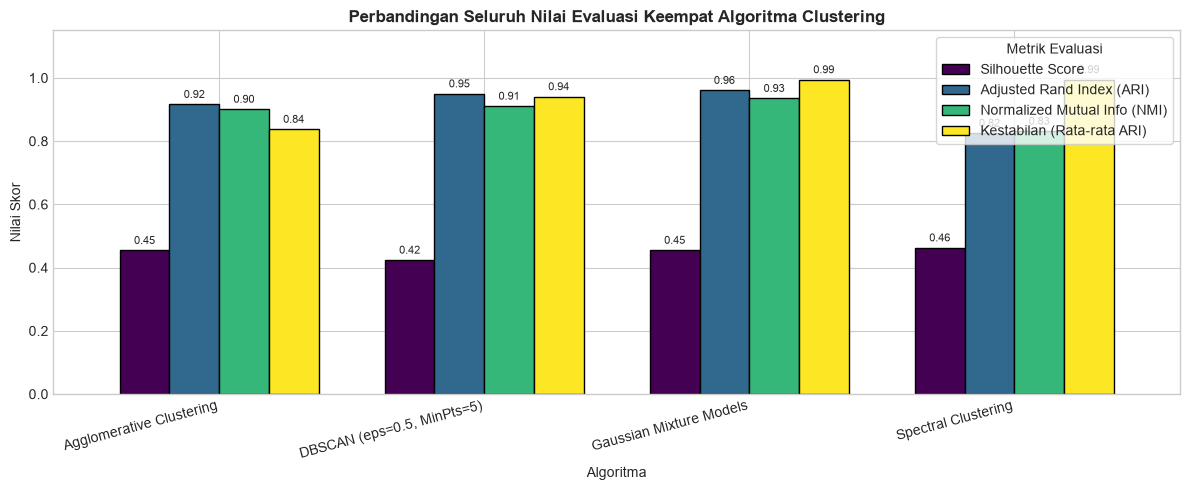

In [80]:
eval_plot_cols = ["Silhouette Score", "Adjusted Rand Index (ARI)", "Normalized Mutual Info (NMI)", "Kestabilan (Rata-rata ARI)"]
fig, ax = plt.subplots(figsize=(12, 5))
summary_comparison[eval_plot_cols].plot(
    kind="bar",
    ax=ax,
    colormap="viridis",
    edgecolor="black",
    width=0.75
)
plt.title("Perbandingan Seluruh Nilai Evaluasi Keempat Algoritma Clustering", fontsize=12, fontweight="bold")
plt.xlabel("Algoritma")
plt.ylabel("Nilai Skor")
plt.xticks(rotation=15, ha="right")
plt.ylim(0, 1.15)
plt.legend(title="Metrik Evaluasi", frameon=True, loc="upper right")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", padding=3, fontsize=8)
plt.tight_layout()
plt.show()